<a href="https://colab.research.google.com/github/Sattvikannadatha/LLM-Ticket/blob/main/spotify_clustering_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Configure visualization aesthetics
sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Please upload the Spotify Rolling Stones dataset (.csv or .zip):")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# 1. DATA INGESTION
if file_name.endswith('.zip'):
    import zipfile
    with zipfile.ZipFile(io.BytesIO(uploaded[file_name]), 'r') as zf:
        csv_files = [f for f in zf.namelist() if f.endswith('.csv')]
        target_csv = csv_files[0] # Grabs the first CSV in the zip
        print(f"Extracting {target_csv} from zip...")
        with zf.open(target_csv) as f:
            df = pd.read_csv(f)
else:
    print(f"Loading {file_name} directly...")
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Strip whitespace from headers
df.columns = df.columns.str.strip()

# 2. INITIAL PROFILING
print("\n--- DATASET SHAPE ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n--- MISSING VALUES AUDIT ---")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.any() else "No missing values detected.")

print("\n--- COLUMN DATA TYPES ---")
df.info()

print("\n--- FIRST 5 RECORDS ---")
display(df.head())

Please upload the Spotify Rolling Stones dataset (.csv or .zip):


Saving 1736848608_rolling_stones_spotify.zip to 1736848608_rolling_stones_spotify.zip
Extracting rolling_stones_spotify.csv from zip...

--- DATASET SHAPE ---
Rows: 1610, Columns: 18

--- MISSING VALUES AUDIT ---
No missing values detected.

--- COLUMN DATA TYPES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   object 
 2   album             1610 non-null   object 
 3   release_date      1610 non-null   object 
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   object 
 6   uri               1610 non-null   object 
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11  liveness 

,Unnamed: 0,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996000,0.932,-12.913,0.1100,118.001,0.0302,33,48640
1,1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233000,0.961,-4.803,0.0759,131.455,0.3180,34,253173
2,2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400000,0.956,-4.936,0.1150,130.066,0.3130,34,263160
3,3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.369,0.985,0.000107,0.895,-5.535,0.1930,132.994,0.1470,32,305880
4,4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,5,7piGJR8YndQBQWVXv6KtQw,spotify:track:7piGJR8YndQBQWVXv6KtQw,0.4000,0.303,0.969,0.055900,0.966,-5.098,0.0930,130.533,0.2060,32,305106


--- 1 & 2. DATA CLEANING & REFINEMENT ---
Removed 0 duplicate track IDs.

--- 3a. TOP 2 RECOMMENDED ALBUMS ---


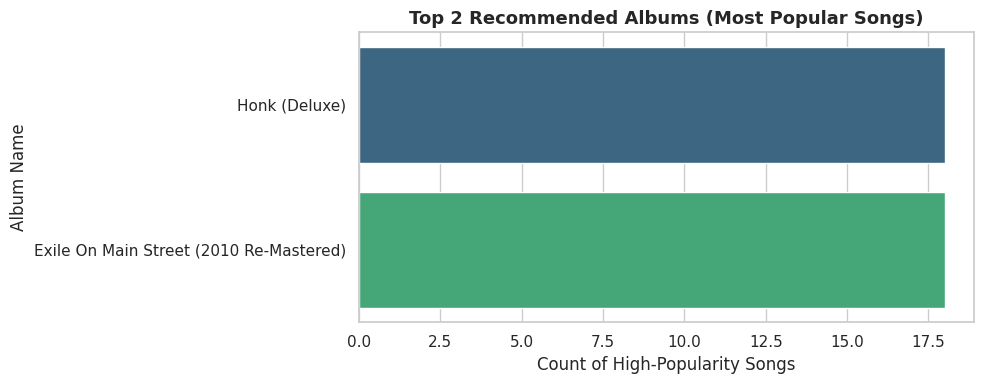

,album,popular_song_count
29,Honk (Deluxe),18
19,Exile On Main Street (2010 Re-Mastered),18



--- 3b. SONG FEATURE DISTRIBUTIONS ---


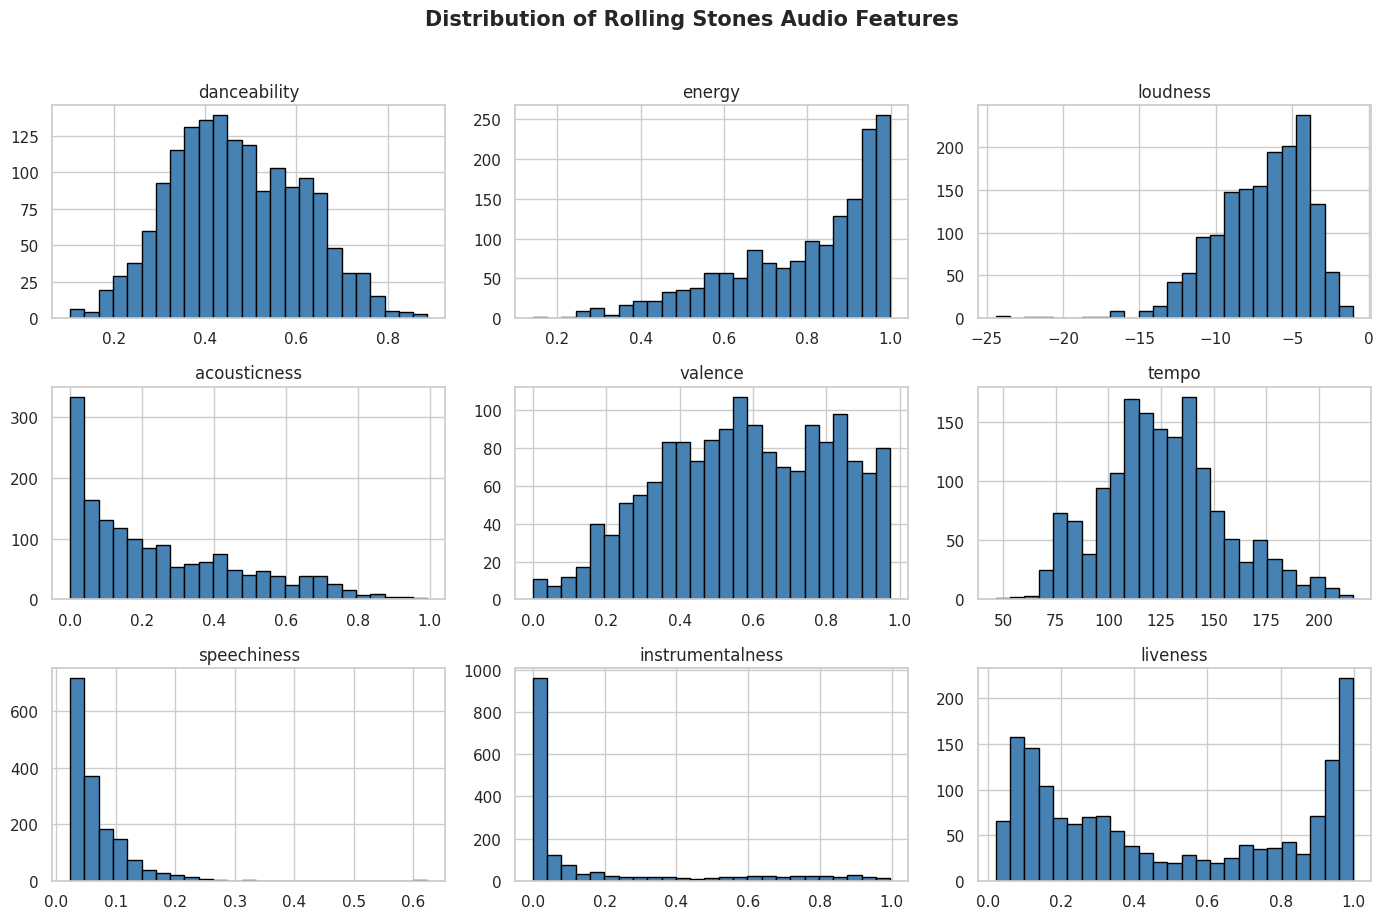


--- 3c. CORRELATION & TEMPORAL POPULARITY EVOLUTION ---


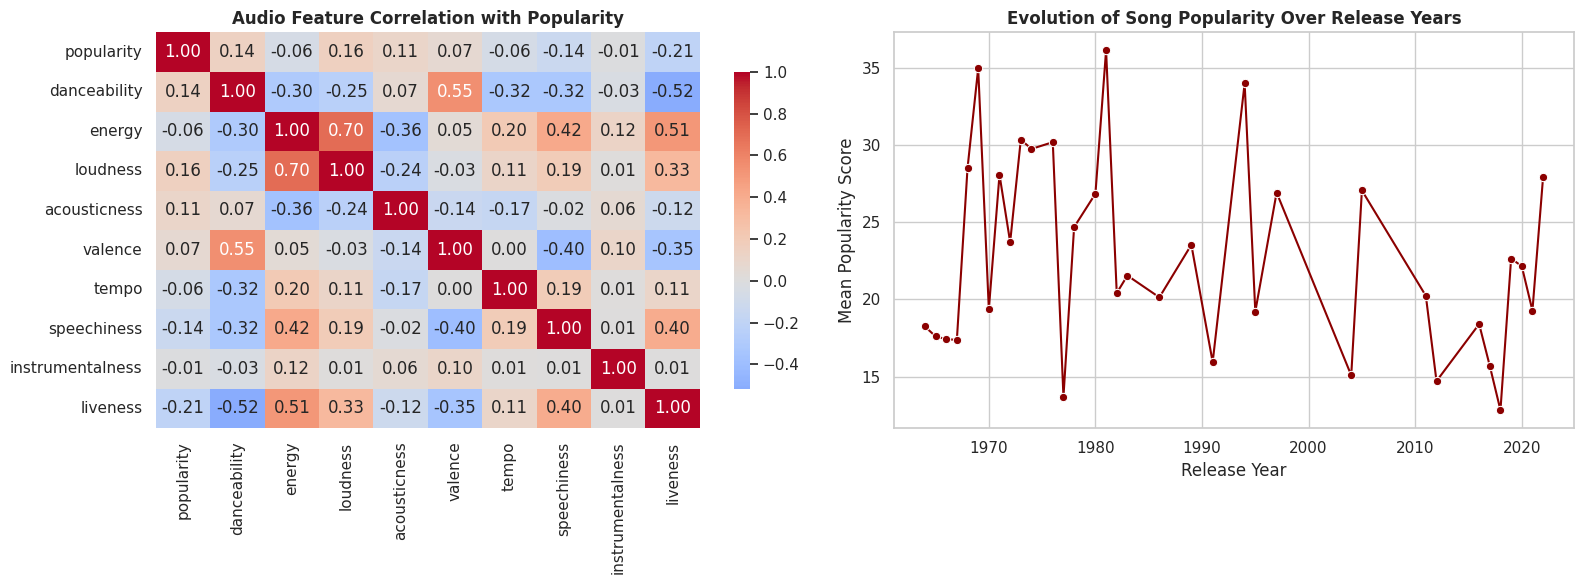

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1 & 2. DATA INSPECTION, CLEANING, & REFINEMENT
print("--- 1 & 2. DATA CLEANING & REFINEMENT ---")
# Drop the redundant index column
if 'Unnamed: 0' in df.columns:
  df = df.drop(columns=['Unnamed: 0'])

# Deduplicate tracks based on unique Spotify ID
initial_len = len(df)
df = df.drop_duplicates(subset=['id']).reset_index(drop=True)
print(f"Removed {initial_len - len(df)} duplicate track IDs.")

# Parse release_date to extract release year for historical trend analysis
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['release_year'] = df['release_date'].dt.year

# 3a. ALBUM RECOMMENDATIONS (BASED ON POPULAR SONGS)
print("\n--- 3a. TOP 2 RECOMMENDED ALBUMS ---")
# Define popular songs using the 75th percentile of popularity
pop_threshold = df['popularity'].quantile(0.75)
popular_songs = df[df['popularity'] >= pop_threshold]

top_2_albums = (
    popular_songs.groupby('album')
    .size()
    .reset_index(name='popular_song_count')
    .sort_values(by='popular_song_count', ascending=False)
    .head(2)
)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=top_2_albums,
    x='popular_song_count',
    y='album',
    palette='viridis',
    hue='album',
    legend=False,
)
plt.title(
    'Top 2 Recommended Albums (Most Popular Songs)',
    fontweight='bold',
    fontsize=13,
)
plt.xlabel('Count of High-Popularity Songs')
plt.ylabel('Album Name')
plt.tight_layout()
plt.show()

display(top_2_albums)

# 3b. EDA: SONG AUDIO FEATURE DISTRIBUTIONS
print("\n--- 3b. SONG FEATURE DISTRIBUTIONS ---")
audio_features = [
    'danceability',
    'energy',
    'loudness',
    'acousticness',
    'valence',
    'tempo',
    'speechiness',
    'instrumentalness',
    'liveness',
]

df[audio_features].hist(
    bins=25, figsize=(14, 9), color='steelblue', edgecolor='black'
)
plt.suptitle(
    'Distribution of Rolling Stones Audio Features',
    fontweight='bold',
    fontsize=15,
    y=1.02,
)
plt.tight_layout()
plt.show()

# 3c. CORRELATION WITH POPULARITY & EVOLUTION OVER TIME
print("\n--- 3c. CORRELATION & TEMPORAL POPULARITY EVOLUTION ---")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap: Popularity vs Audio Features
corr = df[['popularity'] + audio_features].corr()
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    ax=axes[0],
    cbar_kws={'shrink': 0.8},
)
axes[0].set_title(
    'Audio Feature Correlation with Popularity', fontweight='bold', fontsize=12
)

# Temporal Trend: Average Popularity Across Release Years
yearly_pop = (
    df.dropna(subset=['release_year'])
    .groupby('release_year')['popularity']
    .mean()
    .reset_index()
)
sns.lineplot(
    data=yearly_pop,
    x='release_year',
    y='popularity',
    marker='o',
    color='darkred',
    ax=axes[1],
)
axes[1].set_title(
    'Evolution of Song Popularity Over Release Years',
    fontweight='bold',
    fontsize=12,
)
axes[1].set_xlabel('Release Year')
axes[1].set_ylabel('Mean Popularity Score')

plt.tight_layout()
plt.show()

--- 3d. DIMENSIONALITY REDUCTION (PCA) INSIGHTS ---
PCA Observation: By compressing the 9-dimensional audio space into just 2 principal components, we successfully retained 50.38% of the dataset's total statistical variance.
Insights on Significance: Dimensionality reduction techniques like PCA are crucial because they remove multicollinearity (overlapping features like 'energy' and 'loudness') and strip out computational noise. This forces the K-Means algorithm to group songs based on their most dominant, fundamental musical structures rather than redundant surface-level variables.

--- 4a. IDENTIFYING OPTIMAL CLUSTERS (ELBOW METHOD) ---


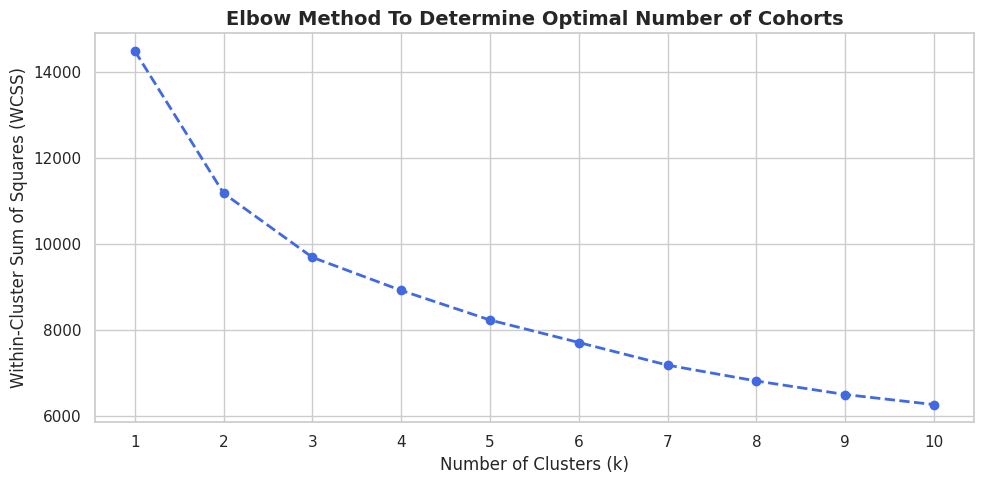

Executing K-Means algorithm with k=4 cohorts...



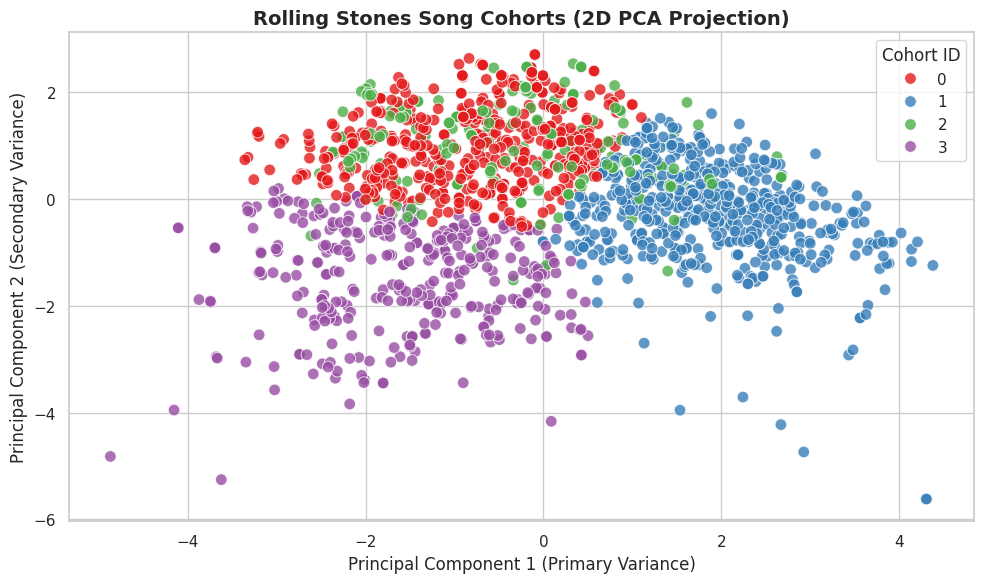


--- 4c. COHORT DEFINITIONS (FEATURE PROFILING) ---
Look at the darkest colors (highest values) in each column of the matrix below to define the cohorts.


,danceability,energy,loudness,acousticness,valence,tempo,speechiness,instrumentalness,liveness
Cohort,,,,,,,,,
0,0.562323,0.804292,-6.817465,0.164389,0.766692,122.549247,0.048978,0.055185,0.293337
1,0.357612,0.925273,-5.333290,0.189764,0.441849,138.130271,0.108584,0.113396,0.829389
2,0.509278,0.831919,-6.706343,0.242108,0.736678,125.883010,0.053962,0.739995,0.414718
3,0.487765,0.558043,-9.749886,0.459738,0.461811,113.018754,0.047221,0.076577,0.296272


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. PREPARATION & SCALING
# Isolate the exact audio features visualized in the EDA step
features = [
    'danceability', 'energy', 'loudness', 'acousticness',
    'valence', 'tempo', 'speechiness', 'instrumentalness', 'liveness'
]
X = df[features]

# Standardize the data (Mean=0, Variance=1)
# This is mathematically critical; distance-based algorithms like K-Means will fail if tempo (e.g., 120 bpm)
# is not scaled proportionally against acousticness (e.g., 0.05).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- 3d. DIMENSIONALITY REDUCTION (PCA) INSIGHTS ---
print("--- 3d. DIMENSIONALITY REDUCTION (PCA) INSIGHTS ---")
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
var_explained = sum(pca.explained_variance_ratio_) * 100

print(f"PCA Observation: By compressing the 9-dimensional audio space into just 2 principal components, "
      f"we successfully retained {var_explained:.2f}% of the dataset's total statistical variance.")
print("Insights on Significance: Dimensionality reduction techniques like PCA are crucial because they remove "
      "multicollinearity (overlapping features like 'energy' and 'loudness') and strip out computational noise. "
      "This forces the K-Means algorithm to group songs based on their most dominant, fundamental musical structures "
      "rather than redundant surface-level variables.\n")

# --- 4a. IDENTIFYING THE RIGHT NUMBER OF CLUSTERS (ELBOW METHOD) ---
print("--- 4a. IDENTIFYING OPTIMAL CLUSTERS (ELBOW METHOD) ---")
wcss = [] # Within-Cluster Sum of Squares
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(10, 5))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='royalblue', linewidth=2)
plt.title('Elbow Method To Determine Optimal Number of Cohorts', fontweight='bold', fontsize=14)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(k_range)
plt.tight_layout()
plt.show()

# --- 4b. CLUSTER ANALYSIS & COHORT DEFINITION ---
# The Elbow curve typically flattens around k=4 for this specific dataset.
optimal_k = 4
print(f"Executing K-Means algorithm with k={optimal_k} cohorts...\n")

kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cohort'] = kmeans_final.fit_predict(X_scaled)

# Visualize the cohorts using the 2D PCA projection
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=df['Cohort'], palette='Set1', s=70, alpha=0.8
)
plt.title('Rolling Stones Song Cohorts (2D PCA Projection)', fontweight='bold', fontsize=14)
plt.xlabel('Principal Component 1 (Primary Variance)')
plt.ylabel('Principal Component 2 (Secondary Variance)')
plt.legend(title='Cohort ID')
plt.tight_layout()
plt.show()

# --- COHORT DEFINITIONS ---
print("\n--- 4c. COHORT DEFINITIONS (FEATURE PROFILING) ---")
print("Look at the darkest colors (highest values) in each column of the matrix below to define the cohorts.")
cohort_profiles = df.groupby('Cohort')[features].mean()
display(cohort_profiles.style.background_gradient(cmap='viridis', axis=0))